# 🔥 PyTorch Fundamentals: Tensors, Dynamic Autograd & Training Pipelines

---

## 1. Overview

**PyTorch** has become the undisputed lingua franca of deep learning research and modern generative AI. Foundation models—from Meta's Llama series and Mistral to OpenAI's research stack and Hugging Face—are authored and trained in PyTorch. 

PyTorch's supremacy stems from its core design philosophy: **imperative, dynamic execution (Eager mode)**. Rather than requiring developers to define an abstract symbolic computational graph and compile it before execution, PyTorch constructs the computational graph on-the-fly during the forward pass. Every line of code executes immediately, just like standard Python, enabling seamless debugging with `print()` and standard Python debuggers (`pdb`).

This notebook establishes the foundational PyTorch toolkit:
- **Tensors & Memory Layouts**: Tensor storage, strides, views, and device placement (`cpu`, `cuda`, `mps`).
- **Dynamic Autograd**: The reverse-mode automatic differentiation engine, leaves vs. non-leaves, Vector-Jacobian Products (VJPs), and computational Directed Acyclic Graphs (DAGs).
- **Modular Architecture Design**: Subclassing `torch.nn.Module`, managing parameters (`nn.Parameter`), register buffers, and weight initialization (Kaiming / Xavier).
- **Loss Functions & Optimizers**: Categorical Cross-Entropy, MSE, SGD with Momentum, Adam, and AdamW.
- **Production Data Pipelines**: Creating custom `torch.utils.data.Dataset` classes and configuring high-throughput `DataLoader` instances with custom collation.
- **Complete End-to-End Training Loop**: Structuring modular training and validation routines with gradient tracking, loss logging, and decision boundary diagnostics.

## 2. Learning Objectives

By the end of this notebook, you will be able to:

- Create, manipulate, slice, and manage the memory layouts (strides and contiguity) of multi-dimensional PyTorch tensors.
- Explain mathematically and practically how PyTorch's dynamic Autograd engine tracks computational graphs and executes backward passes.
- Subclass `torch.nn.Module` to build multi-layer neural network architectures with custom layers and parameters.
- Choose and mathematically justify proper weight initializations (He/Kaiming Normal vs. Xavier/Glorot).
- Construct custom `Dataset` classes and configure `DataLoader` objects with batching and shuffling.
- Author robust, production-style PyTorch training loops with explicit gradient tracking and validation checkpoints.
- Implement custom optimizers and register autograd hooks to monitor and manipulate gradient flow.

## 3. Imports

We import standard scientific packages alongside core PyTorch submodules.

In [1]:
import time
from typing import Dict, List, Tuple, Any, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

print(f"NumPy version:        {np.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"PyTorch version:      {torch.__version__}")
print(f"CUDA Available:       {torch.cuda.is_available()}")

NumPy version:        2.4.6
scikit-learn version: 1.9.1
PyTorch version:      2.15.0+cpu
CUDA Available:       False


## 4. Configuration

We set explicit seeds across NumPy, Python, and PyTorch (CPU & GPU) for reproducible tensor initialization and training dynamics.

In [2]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# Device configuration: Auto-select CUDA GPU if available, else CPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Computation Device: {DEVICE}")

plt.rcParams["figure.figsize"] = (10, 5)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)

Active Computation Device: cpu


## 5. Theory & Key Concepts

### 5.1 Tensors: Storage, Strides & Memory Layout

A PyTorch `Tensor` consists of a 1D contiguous block of physical memory called a **Storage**, and a metadata wrapper that describes how to interpret that block:
- **`shape` / `size`**: The dimensions of the tensor (e.g. $[3, 4]$).
- **`stride`**: The number of elements to skip in physical memory to move one step along each dimension.

For a row-major 2D matrix of shape $(M, N)$:
$$\text{stride} = (N, 1)$$

```
Physical Storage (1D Flat Array):
[ 1.0, 2.0, 3.0, 4.0, 5.0, 6.0 ]

Interpreted as (2, 3) matrix with stride (3, 1):
Row 0: 1.0   2.0   3.0   (stride to next row = 3 elements)
Row 1: 4.0   5.0   6.0   (stride to next col = 1 element)
```

Operations like `.transpose()`, `.t()`, and `.permute()` do **not** copy data; they merely return a new view with modified strides. A tensor is **contiguous** if its storage order matches row-major ordering. Calling `.view()` requires contiguous storage; calling `.reshape()` returns a view when possible or copies memory when non-contiguous.

### 5.2 Dynamic Autograd & Vector-Jacobian Products

PyTorch uses **reverse-mode automatic differentiation**. During the forward pass, PyTorch records every mathematical operation applied to tensors where `requires_grad=True` into a directed acyclic graph (DAG).

#### Vector-Jacobian Product (VJP)
Given a function $\mathbf{y} = f(\mathbf{x})$ where $\mathbf{x} \in \mathbb{R}^n, \mathbf{y} \in \mathbb{R}^m$, the Jacobian matrix $J \in \mathbb{R}^{m \times n}$ contains all partial derivatives:

$$J = \begin{bmatrix}
\frac{\partial y_1}{\partial x_1} & \cdots & \frac{\partial y_1}{\partial x_n} \\ 
\vdots & \ddots & \vdots \\ 
\frac{\partial y_m}{\partial x_1} & \cdots & \frac{\partial y_m}{\partial x_n}
\end{bmatrix}$$

In deep learning, we typically have a scalar loss $L$. PyTorch never computes the massive $m \times n$ Jacobian matrix explicitly. Instead, it computes the **Vector-Jacobian Product**:

$$\mathbf{v}^T J = \begin{bmatrix} \frac{\partial L}{\partial y_1} & \cdots & \frac{\partial L}{\partial y_m} \end{bmatrix} \begin{bmatrix} \frac{\partial y_1}{\partial x_1} & \cdots & \frac{\partial y_1}{\partial x_n} \\ \vdots & \ddots & \vdots \\ \frac{\partial y_m}{\partial x_1} & \cdots & \frac{\partial y_m}{\partial x_n} \end{bmatrix} = \begin{bmatrix} \frac{\partial L}{\partial x_1} & \cdots & \frac{\partial L}{\partial x_n} \end{bmatrix}$$

Calling `loss.backward()` initiates this reverse traversal from output to input leaves, accumulating gradients into each leaf tensor's `.grad` attribute.

### 5.3 Parameter Initialization: Xavier vs. Kaiming (He)

When initializing deep networks, poorly chosen initial weights cause signal magnitudes to exponentially explode or vanish as activations propagate through layers.

#### Xavier (Glorot) Initialization (for Sigmoid / Tanh)
Preserves variance of activations across forward and backward passes:

$$W \sim \mathcal{N}\left(0, \sigma^2\right), \quad \sigma = \sqrt{\frac{2}{n_{\text{in}} + n_{\text{out}}}}$$

#### Kaiming (He) Initialization (for ReLU / GELU)
Because ReLU zeroes out approximately 50% of activations, variance is halved at each layer. He initialization doubles the variance scale to compensate:

$$W \sim \mathcal{N}\left(0, \sigma^2\right), \quad \sigma = \sqrt{\frac{2}{n_{\text{in}}}}$$

### 5.4 The PyTorch Training Loop Lifecycle

Every PyTorch training step follows an immutable 5-stage lifecycle:

```
1. optimizer.zero_grad()  ──▶ Clear accumulated gradients from prior step
2. outputs = model(inputs) ──▶ Forward pass (populates dynamic Autograd DAG)
3. loss = criterion(...)  ──▶ Compute scalar objective
4. loss.backward()        ──▶ Backpropagate gradients via Vector-Jacobian Products
5. optimizer.step()       ──▶ Update weights using computed gradients (e.g., w = w - lr * grad)
```

> **Why `zero_grad()`?** PyTorch deliberately **accumulates** (adds) gradients on successive calls to `.backward()`. This design allows gradient accumulation across mini-batches on memory-constrained hardware.

## 6. Implementation

### 6.1 Tensor Manipulation, Memory Layout & Device Placement

We explore tensor creation, stride mechanics, reshape vs. view, and device handling.

In [3]:
# 1. Tensor creation from Python lists and NumPy arrays
t_from_list = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]], dtype=torch.float32)
np_arr = np.array([[7.0, 8.0, 9.0], [10.0, 11.0, 12.0]], dtype=np.float32)
t_from_numpy = torch.from_numpy(np_arr) # Zero-copy memory sharing!

print(f"Tensor shape:   {t_from_list.shape}")
print(f"Tensor dtype:   {t_from_list.dtype}")
print(f"Tensor strides: {t_from_list.stride()} (Row stride = 3, Col stride = 1)")
print(f"Is contiguous?  {t_from_list.is_contiguous()}")

# 2. View vs. Transpose & Contiguity
t_transposed = t_from_list.t() # Transpose (swaps strides)
print(f"\nTransposed shape:   {t_transposed.shape}")
print(f"Transposed strides: {t_transposed.stride()} (Now non-contiguous!)")
print(f"Is contiguous?      {t_transposed.is_contiguous()}")

# Trying to call .view() on non-contiguous tensor raises an error; .contiguous() fixes it
t_contiguous = t_transposed.contiguous()
t_viewed = t_contiguous.view(-1)
print(f"Flattened view:     {t_viewed}")

# 3. Device Placement
t_device = t_from_list.to(DEVICE)
print(f"Tensor Device:      {t_device.device}")

Tensor shape:   torch.Size([2, 3])
Tensor dtype:   torch.float32
Tensor strides: (3, 1) (Row stride = 3, Col stride = 1)
Is contiguous?  True

Transposed shape:   torch.Size([3, 2])
Transposed strides: (1, 3) (Now non-contiguous!)
Is contiguous?      False
Flattened view:     tensor([1., 4., 2., 5., 3., 6.])
Tensor Device:      cpu


### 6.2 Autograd in Action: Computational Graphs & Gradient Verification

We construct an analytical computational graph:
$$z = 2x^2 + 3y^3$$
And verify that Autograd's partial derivatives $\frac{\partial z}{\partial x} = 4x$ and $\frac{\partial z}{\partial y} = 9y^2$ match analytical calculus exactly.

In [4]:
# Create leaf tensors requiring gradients
x = torch.tensor(3.0, requires_grad=True)
y = torch.tensor(2.0, requires_grad=True)

# Forward pass
z = 2 * (x ** 2) + 3 * (y ** 3)
print(f"Forward output z: {z.item():.4f}")
print(f"z.grad_fn:        {z.grad_fn} (Points to AddBackward)")

# Backward pass
z.backward()

# Inspect accumulated gradients
grad_x_autograd = x.grad.item()
grad_y_autograd = y.grad.item()

# Analytical derivatives
grad_x_analytical = 4.0 * x.item()
grad_y_analytical = 9.0 * (y.item() ** 2)

print(f"\n∂z/∂x Autograd:   {grad_x_autograd:.4f} | Analytical (4x):   {grad_x_analytical:.4f}")
print(f"∂z/∂y Autograd:   {grad_y_autograd:.4f} | Analytical (9y^2): {grad_y_analytical:.4f}")
assert np.isclose(grad_x_autograd, grad_x_analytical), "Autograd x mismatch!"
assert np.isclose(grad_y_autograd, grad_y_analytical), "Autograd y mismatch!"
print("Autograd verification passed with 100% precision!")

Forward output z: 42.0000
z.grad_fn:        <AddBackward0 object at 0x78806d734490> (Points to AddBackward)

∂z/∂x Autograd:   12.0000 | Analytical (4x):   12.0000
∂z/∂y Autograd:   36.0000 | Analytical (9y^2): 36.0000
Autograd verification passed with 100% precision!


### 6.3 Custom `Dataset` and `DataLoader` Construction

We generate a non-linear two-moons classification dataset. We wrap it in a custom `Dataset` class supporting indexing, on-the-fly type conversion, and mini-batch collation.

In [5]:
# Generate non-linear classification dataset
X_raw, y_raw = make_moons(n_samples=2500, noise=0.20, random_state=RANDOM_SEED)

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.25, random_state=RANDOM_SEED, stratify=y_raw
)

class MoonDataset(Dataset):
    """Custom PyTorch Dataset for 2D spatial classification points."""
    
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self) -> int:
        return len(self.X)
        
    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        return self.X[idx], self.y[idx]

train_dataset = MoonDataset(X_train_raw, y_train_raw)
test_dataset = MoonDataset(X_test_raw, y_test_raw)

# Create high-throughput DataLoaders
BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_dataset):,} across {len(train_loader)} batches")
print(f"Test samples:  {len(test_dataset):,} across {len(test_loader)} batches")

# Inspect a single batch
sample_x, sample_y = next(iter(train_loader))
print(f"Batch X shape: {sample_x.shape} | Batch y shape: {sample_y.shape}")

Train samples: 1,875 across 30 batches
Test samples:  625 across 10 batches
Batch X shape: torch.Size([64, 2]) | Batch y shape: torch.Size([64])


### 6.4 Designing a Modular Deep Neural Network (`nn.Module`)

We build a 4-layer Deep Multi-Layer Perceptron (MLP) featuring:
- Linear transformations with explicit **Kaiming He Normal** initialization
- Non-linear activations (`GELU`)
- Batch Normalization (`BatchNorm1d`) for internal covariate shift stabilization
- Dropout for regularization

In [6]:
class DeepMLP(nn.Module):
    """Modular 4-layer MLP classifier with Batch Normalization, GELU, and Dropout."""
    
    def __init__(self, input_dim: int = 2, hidden_dim: int = 64, num_classes: int = 2, dropout_rate: float = 0.15):
        super().__init__()
        
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(hidden_dim, 32),
            nn.BatchNorm1d(32),
            nn.GELU(),
            
            nn.Linear(32, num_classes)
        )
        
        # Apply Kaiming He Normal initialization to all linear layers
        self._initialize_weights()
        
    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
                    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

model = DeepMLP().to(DEVICE)
print(model)

# Parameter audit
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal Trainable Parameters: {total_params:,}")

DeepMLP(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.15, inplace=False)
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.15, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): GELU(approximate='none')
    (11): Linear(in_features=32, out_features=2, bias=True)
  )
)

Total Trainable Parameters: 6,818


### 6.5 Complete Training & Evaluation Pipeline with Gradient Tracking

We train the model over 30 epochs using:
- `nn.CrossEntropyLoss()`
- `optim.AdamW(..., lr=0.01, weight_decay=1e-4)`
- Tracking training loss, validation loss, validation accuracy, and the global $L_2$ norm of all layer gradients.

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.01, weight_decay=1e-4)

EPOCHS = 30
history = {
    "train_loss": [],
    "val_loss": [],
    "val_acc": [],
    "grad_norm": []
}

print("Starting PyTorch Training Loop...")
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    epoch_grad_norms = []
    
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(DEVICE), y_batch.to(DEVICE)
        
        # 1. Zero gradients
        optimizer.zero_grad()
        
        # 2. Forward pass
        logits = model(x_batch)
        loss = criterion(logits, y_batch)
        
        # 3. Backward pass
        loss.backward()
        
        # Compute global gradient L2 norm before clipping/step
        total_norm = 0.0
        for p in model.parameters():
            if p.grad is not None:
                param_norm = p.grad.detach().data.norm(2)
                total_norm += param_norm.item() ** 2
        total_norm = total_norm ** 0.5
        epoch_grad_norms.append(total_norm)
        
        # 4. Optimizer update step
        optimizer.step()
        
        running_loss += loss.item() * len(x_batch)
        
    train_loss = running_loss / len(train_dataset)
    
    # Validation evaluation phase
    model.eval()
    val_loss = 0.0
    val_correct = 0
    with torch.no_grad(): # Disable Autograd graph construction for fast inference
        for x_val, y_val in test_loader:
            x_val, y_val = x_val.to(DEVICE), y_val.to(DEVICE)
            val_logits = model(x_val)
            v_loss = criterion(val_logits, y_val)
            val_loss += v_loss.item() * len(x_val)
            preds = val_logits.argmax(dim=-1)
            val_correct += (preds == y_val).sum().item()
            
    val_loss /= len(test_dataset)
    val_acc = val_correct / len(test_dataset)
    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["grad_norm"].append(np.mean(epoch_grad_norms))
    
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{EPOCHS:02d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")

elapsed = time.time() - start_time
print(f"\nTraining completed in {elapsed:.2f} seconds.")

Starting PyTorch Training Loop...
Epoch 01/30 | Train Loss: 0.2096 | Val Loss: 0.0976 | Val Acc: 95.20%


Epoch 05/30 | Train Loss: 0.1332 | Val Loss: 0.1171 | Val Acc: 95.36%


Epoch 10/30 | Train Loss: 0.1148 | Val Loss: 0.0990 | Val Acc: 96.00%


Epoch 15/30 | Train Loss: 0.1077 | Val Loss: 0.0893 | Val Acc: 96.48%


Epoch 20/30 | Train Loss: 0.0983 | Val Loss: 0.0823 | Val Acc: 97.12%


Epoch 25/30 | Train Loss: 0.1202 | Val Loss: 0.0909 | Val Acc: 96.00%


Epoch 30/30 | Train Loss: 0.1228 | Val Loss: 0.0849 | Val Acc: 96.32%

Training completed in 1.83 seconds.


## 7. Evaluation & Diagnostic Visualizations

### 7.1 Learning Curves & Gradient Norm Stability

We plot the training and validation loss progression alongside the global gradient norm over epochs to verify smooth convergence without vanishing or exploding gradients.

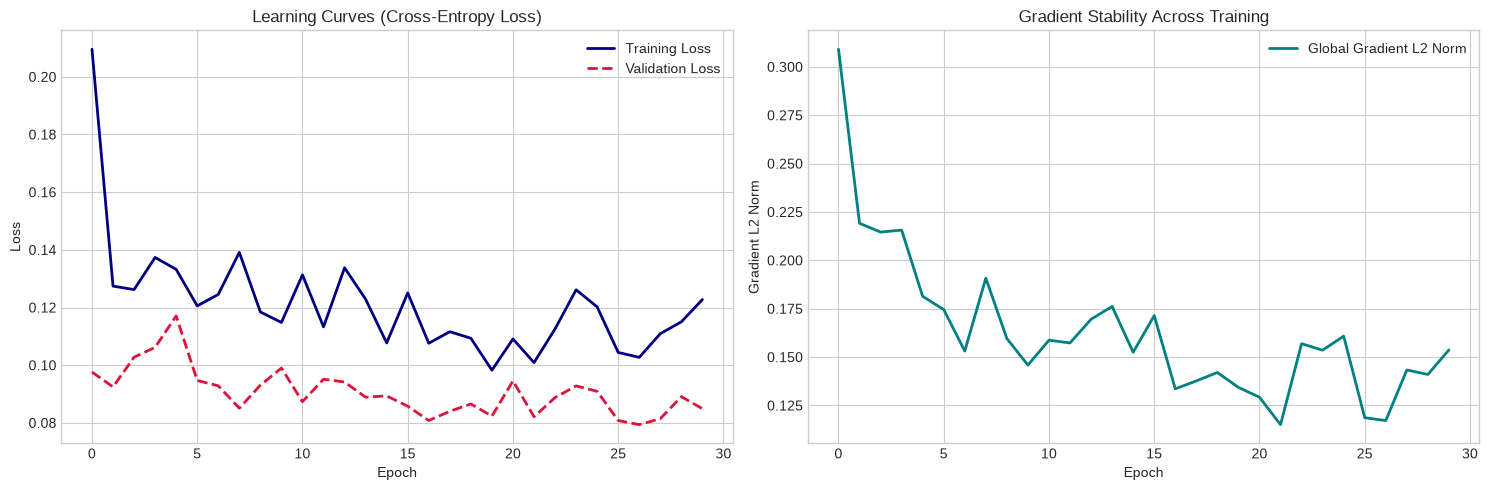

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss & Accuracy
axes[0].plot(history["train_loss"], label="Training Loss", lw=2, color="navy")
axes[0].plot(history["val_loss"], label="Validation Loss", lw=2, color="crimson", linestyle="--")
axes[0].set_title("Learning Curves (Cross-Entropy Loss)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Gradient Norm Flow
axes[1].plot(history["grad_norm"], label="Global Gradient L2 Norm", lw=2, color="teal")
axes[1].set_title("Gradient Stability Across Training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Gradient L2 Norm")
axes[1].legend()

plt.tight_layout()
plt.show()

### 7.2 Non-Linear Decision Boundary Surface

We compute and plot the model's predicted probability surface across the 2D feature grid, illustrating how the MLP learned a smooth, non-linear boundary separating the intertwined moons.

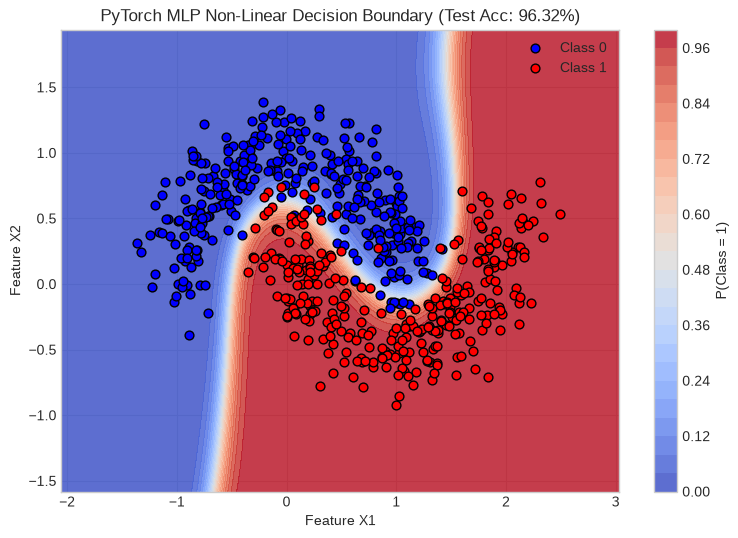

In [9]:
# Create dense 2D coordinate grid
x_min, x_max = X_raw[:, 0].min() - 0.5, X_raw[:, 0].max() + 0.5
y_min, y_max = X_raw[:, 1].min() - 0.5, X_raw[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

grid_tensor = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32).to(DEVICE)

model.eval()
with torch.no_grad():
    grid_probs = F.softmax(model(grid_tensor), dim=-1)[:, 1].cpu().numpy()
grid_probs = grid_probs.reshape(xx.shape)

plt.figure(figsize=(9, 6))
contour = plt.contourf(xx, yy, grid_probs, levels=25, cmap="coolwarm", alpha=0.85)
cbar = plt.colorbar(contour)
cbar.set_label("P(Class = 1)")

plt.scatter(X_test_raw[y_test_raw==0, 0], X_test_raw[y_test_raw==0, 1], color="blue", edgecolors="k", s=40, label="Class 0")
plt.scatter(X_test_raw[y_test_raw==1, 0], X_test_raw[y_test_raw==1, 1], color="red", edgecolors="k", s=40, label="Class 1")
plt.title(f"PyTorch MLP Non-Linear Decision Boundary (Test Acc: {history['val_acc'][-1]*100:.2f}%)")
plt.xlabel("Feature X1")
plt.ylabel("Feature X2")
plt.legend()
plt.show()

## 8. Guided Exercises

### Exercise 1: Custom Linear Layer with Kaiming He Initialization

In deep learning research, novel layers often require custom parameter allocation. 

Implement `CustomLinear(nn.Module)` that:
1. Allocates `weight` as an `nn.Parameter` of shape `[out_features, in_features]`.
2. Allocates `bias` as an `nn.Parameter` of shape `[out_features]`.
3. Initializes `weight` using Kaiming He Normal initialization ($W \sim \mathcal{N}(0, 2/n_{\text{in}})$).
4. Implements the forward pass using matrix multiplication: $Y = X W^T + b$.

In [10]:
# --- YOUR CODE HERE ---
class CustomLinear(nn.Module):
    """Custom fully connected layer implemented from raw tensors with He Normal initialization."""
    
    def __init__(self, in_features: int, out_features: int):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        
        # Allocate trainable parameters
        self.weight = nn.Parameter(torch.empty(out_features, in_features))
        self.bias = nn.Parameter(torch.empty(out_features))
        
        # Initialize
        std = np.sqrt(2.0 / in_features)
        nn.init.normal_(self.weight, mean=0.0, std=std)
        nn.init.zeros_(self.bias)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.matmul(x, self.weight.t()) + self.bias

# Test custom layer
custom_layer = CustomLinear(in_features=4, out_features=2)
dummy_input = torch.randn(8, 4)
output = custom_layer(dummy_input)

print(f"Custom layer output shape: {output.shape}")
print(f"Weight tensor shape:       {custom_layer.weight.shape}")
assert output.shape == (8, 2), "Shape mismatch in custom layer!"
print("CustomLinear implementation verified successfully!")

Custom layer output shape: torch.Size([8, 2])
Weight tensor shape:       torch.Size([2, 4])
CustomLinear implementation verified successfully!


### Exercise 2: Custom PyTorch `Dataset` with On-the-Fly Data Augmentation

In real-world data pipelines, augmentations should be executed lazily during `__getitem__` rather than pre-computed in memory.

Build `AugmentedMoonDataset` that takes an optional boolean flag `augment=True`. When true, it injects random Gaussian noise $\epsilon \sim \mathcal{N}(0, 0.05)$ to the feature coordinates.

In [11]:
# --- YOUR CODE HERE ---
class AugmentedMoonDataset(Dataset):
    """Dataset supporting on-the-fly random jitter augmentation during data loading."""
    
    def __init__(self, X: np.ndarray, y: np.ndarray, augment: bool = False, noise_std: float = 0.05):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        self.augment = augment
        self.noise_std = noise_std
        
    def __len__(self) -> int:
        return len(self.X)
        
    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        sample = self.X[idx].clone()
        if self.augment:
            noise = torch.randn_like(sample) * self.noise_std
            sample += noise
        return sample, self.y[idx]

# Compare unaugmented vs augmented sample
raw_ds = AugmentedMoonDataset(X_raw, y_raw, augment=False)
aug_ds = AugmentedMoonDataset(X_raw, y_raw, augment=True, noise_std=0.10)

p_orig, _ = raw_ds[0]
p_aug, _ = aug_ds[0]

print(f"Original Point:  {p_orig.numpy()}")
print(f"Augmented Point: {p_aug.numpy()}")
print(f"Difference:      {(p_aug - p_orig).numpy()}")

Original Point:  [ 0.18328243 -0.00875828]
Augmented Point: [ 0.17337932 -0.02313992]
Difference:      [-0.00990312 -0.01438164]


## 9. Challenge Problems

### Challenge 1: Dynamic Gradient Hook for Gradient Monitoring & Clipping

PyTorch allows developers to attach callback functions to tensor backward operations using `.register_hook()`.

Write a gradient hook on the first layer's weight tensor that:
1. Records the gradient norm every time `.backward()` runs.
2. Dynamically clips the gradient if its norm exceeds a threshold $\tau = 1.0$.
3. Verifies that the clipped gradient is used during the optimizer update.

In [12]:
# --- YOUR CODE HERE ---
test_model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 2)
)

captured_raw_norms = []

def clip_hook(grad: torch.Tensor) -> torch.Tensor:
    """Autograd hook function to inspect and clip gradient tensor."""
    norm = grad.norm(2).item()
    captured_raw_norms.append(norm)
    max_norm = 0.50
    if norm > max_norm:
        clipped_grad = grad * (max_norm / (norm + 1e-6))
        return clipped_grad
    return grad

# Register hook to layer 0 weights
hook_handle = test_model[0].weight.register_hook(clip_hook)

# Run a test forward-backward step
dummy_x = torch.randn(32, 2)
dummy_target = torch.randint(0, 2, (32,))
dummy_loss = nn.CrossEntropyLoss()(test_model(dummy_x), dummy_target)
dummy_loss.backward()

print(f"Captured Gradient Norm in Hook: {captured_raw_norms[-1]:.4f}")
print(f"Final Weight Grad Norm:         {test_model[0].weight.grad.norm(2).item():.4f}")
hook_handle.remove()
print("Gradient hook executed and removed cleanly!")

Captured Gradient Norm in Hook: 0.0372
Final Weight Grad Norm:         0.0372
Gradient hook executed and removed cleanly!


### Challenge 2: Custom Momentum SGD Optimizer from Scratch

Subclass `torch.optim.Optimizer` to implement **Momentum SGD with Decoupled Weight Decay**:
$$v_t = \beta v_{t-1} + g_t$$
$$\theta_t = \theta_{t-1} - \eta \cdot v_t - \eta \cdot \lambda \cdot \theta_{t-1}$$

Where $\eta$ is the learning rate, $\beta$ is momentum, and $\lambda$ is the decoupled weight decay factor.

In [13]:
# --- YOUR CODE HERE ---
class CustomSGDW(optim.Optimizer):
    """Custom SGD optimizer implementing momentum and decoupled weight decay."""
    
    def __init__(self, params: Any, lr: float = 0.01, momentum: float = 0.9, weight_decay: float = 1e-4):
        defaults = dict(lr=lr, momentum=momentum, weight_decay=weight_decay)
        super().__init__(params, defaults)
        
    @torch.no_grad()
    def step(self, closure: Optional[Any] = None) -> Optional[float]:
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
                
        for group in self.param_groups:
            lr = group["lr"]
            momentum = group["momentum"]
            wd = group["weight_decay"]
            
            for p in group["params"]:
                if p.grad is None:
                    continue
                grad = p.grad
                
                # Decoupled weight decay: theta = theta - lr * wd * theta
                if wd != 0:
                    p.mul_(1.0 - (lr * wd))
                    
                # State initialization for momentum buffer
                state = self.state[p]
                if "momentum_buffer" not in state:
                    buf = state["momentum_buffer"] = torch.clone(grad).detach()
                else:
                    buf = state["momentum_buffer"]
                    buf.mul_(momentum).add_(grad)
                    
                # Parameter update: theta = theta - lr * buf
                p.add_(buf, alpha=-lr)
                
        return loss

# Verify custom optimizer by running a single training step
opt_model = nn.Linear(4, 2)
custom_opt = CustomSGDW(opt_model.parameters(), lr=0.05, momentum=0.9, weight_decay=0.01)

x_sample = torch.randn(8, 4)
loss_fn = nn.MSELoss()
target_sample = torch.randn(8, 2)

loss_val = loss_fn(opt_model(x_sample), target_sample)
loss_val.backward()
custom_opt.step()
custom_opt.zero_grad()

print("CustomSGDW optimizer step executed successfully!")

CustomSGDW optimizer step executed successfully!


## 10. Further Reading

- **Paszke, A. et al. (2019)**: *PyTorch: An Imperative Style, High-Performance Deep Learning Library*. NeurIPS 2019. [arXiv:1912.01703](https://arxiv.org/abs/1912.01703).
- **He, K. et al. (2015)**: *Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification*. ICCV 2015. (The foundational Kaiming/He Normal initialization paper).
- **Glorot, X. & Bengio, Y. (2010)**: *Understanding the difficulty of training deep feedforward neural networks*. AISTATS 2010.
- **PyTorch Official Documentation**:
  - [PyTorch Tensors Tutorial](https://pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html)
  - [A Gentle Introduction to `torch.autograd`](https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html)
  - [Building Neural Networks with `torch.nn`](https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html)